<a href="https://colab.research.google.com/github/cahyaikhsani/Portofolio/blob/main/3A_23090250002_CahyaIKhsani_Regresilogistik.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df = pd.read_csv('/content/dataset_harga_rumah_jateng.csv')

print("Ukuran data:", df.shape)
df.head()

Ukuran data: (1200, 5)


,nomor,luas_bangunan,jumlah_kamar,lokasi,harga_juta
0,1,65.0,2,Kota Surakarta,519.5
1,2,63.0,2,Kabupaten Klaten,359.0
2,3,39.0,2,Kabupaten Sukoharjo,294.0
3,4,66.0,1,Kabupaten Semarang,376.5
4,5,94.0,2,Kabupaten Semarang,552.5


In [ ]:
print("Jumlah data kosong tiap kolom:")
print(df.isnull().sum())

Jumlah data kosong tiap kolom:
nomor             0
luas_bangunan    72
jumlah_kamar      0
lokasi            0
harga_juta        0
dtype: int64


Text(0.5, 1.0, 'Hubungan Luas Bangunan dengan Harga Rumah')

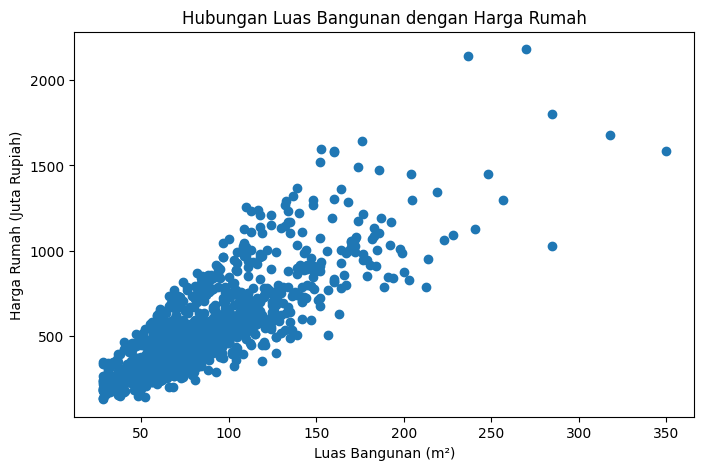

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(df['luas_bangunan'], df['harga_juta'])

plt.xlabel('Luas Bangunan (m²)')
plt.ylabel('Harga Rumah (Juta Rupiah)')
plt.title('Hubungan Luas Bangunan dengan Harga Rumah')

In [ ]:
#Membagi data menjadi data latih dan data uji
train, test = train_test_split(
    df,
    test_size=0.25,
    random_state=42
)

print("Jumlah data latih:", len(train))
print("Jumlah data uji  :", len(test))

Jumlah data latih: 900
Jumlah data uji  : 300


In [ ]:
# Menghitung median luas bangunan dari data latih
median_luas = train['luas_bangunan'].median()

print("Median luas bangunan data latih:", median_luas)


Median luas bangunan data latih: 78.0


In [ ]:
# Mengisi nilai kosong dengan median data latih
train['luas_bangunan'] = train['luas_bangunan'].fillna(median_luas)
test['luas_bangunan'] = test['luas_bangunan'].fillna(median_luas)

print("Data kosong setelah diisi:")
print("Train:", train['luas_bangunan'].isnull().sum())
print("Test:", test['luas_bangunan'].isnull().sum())

Data kosong setelah diisi:
Train: 0
Test: 0


In [ ]:
# One-hot encoding untuk kolom lokasi
lokasi_train = pd.get_dummies(
    train['lokasi'],
    prefix='lokasi',
    dtype=int
)
lokasi_test = pd.get_dummies(
    test['lokasi'],
    prefix='lokasi',
    dtype=int
)
# Menyamakan kolom data train dan test
lokasi_test = lokasi_test.reindex(
    columns=lokasi_train.columns,
    fill_value=0
)
print("Jumlah kolom lokasi:", len(lokasi_train.columns))
lokasi_train.head()

Jumlah kolom lokasi: 15


,lokasi_Kabupaten Banyumas,lokasi_Kabupaten Boyolali,lokasi_Kabupaten Demak,lokasi_Kabupaten Karanganyar,lokasi_Kabupaten Kendal,lokasi_Kabupaten Klaten,lokasi_Kabupaten Kudus,lokasi_Kabupaten Semarang,lokasi_Kabupaten Sragen,lokasi_Kabupaten Sukoharjo,lokasi_Kabupaten Wonogiri,lokasi_Kota Magelang,lokasi_Kota Salatiga,lokasi_Kota Semarang,lokasi_Kota Surakarta
845,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
986,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
227,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1192,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
671,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0


In [ ]:
print("Data train setelah prepocessing:")
print(train.head())

print("\nJumlah data train:", len(train))
print("jumlah data test:", len(test))
print("Median yang digunakan:", median_luas)

Data train setelah prepocessing:
      nomor  luas_bangunan  jumlah_kamar              lokasi  harga_juta
845     846           39.0             2     Kabupaten Kudus       242.0
986     987           64.0             2      Kota Surakarta       634.0
227     228           84.0             2  Kabupaten Banyumas       499.5
1192   1193           97.0             4    Kabupaten Sragen       370.5
671     672           78.0             3    Kabupaten Kendal       422.0

Jumlah data train: 900
jumlah data test: 300
Median yang digunakan: 78.0


In [ ]:
# MODEL A
# Variabel yang digunakan hanya luas_bangunan

X_train_A = train[['luas_bangunan']]
X_test_A = test[['luas_bangunan']]

y_train = train['harga_juta']
y_test = test['harga_juta']

model_A = LinearRegression()
model_A.fit(X_train_A, y_train)

print("Intercept (a):", model_A.intercept_)
print("Koefisien luas bangunan (b):", model_A.coef_[0])

Intercept (a): 59.34997442741951
Koefisien luas bangunan (b): 5.613134720203099


In [ ]:
# Prediksi data uji menggunakan model A
pred_A = model_A.predict(X_test_A)

# Menghitung MAE, RMSE, dan R2
mae_A = mean_absolute_error(y_test, pred_A)
rmse_A = np.sqrt(mean_squared_error(y_test, pred_A))
r2_A = r2_score(y_test, pred_A)

print("Hasil Evaluasi Model A")
print("MAE  :", mae_A)
print("RMSE :", rmse_A)
print("R2   :", r2_A)

Hasil Evaluasi Model A
MAE  : 125.03272388893033
RMSE : 169.37546463723172
R2   : 0.6515843449480461


In [ ]:
# MODEL B
# Menggabungkan luas bangunan, jumlah kamar, dan lokasi

X_train_B = pd.concat([
  train[['luas_bangunan', 'jumlah_kamar']].reset_index(drop=True),
  lokasi_train.reset_index(drop=True)
], axis=1)

X_test_B = pd.concat([
  test[['luas_bangunan', 'jumlah_kamar']].reset_index(drop=True),
  lokasi_test.reset_index(drop=True)
], axis=1)

model_B = LinearRegression()
model_B.fit(X_train_B, y_train.reset_index(drop=True))

print("Model B berhasil dibuat.")
print("Jumlah fitur:", X_train_B.shape[1])

Model B berhasil dibuat.
Jumlah fitur: 17


In [ ]:
# Prediksi data uji menggunakan Model B
pred_B = model_B.predict(X_test_B)

# Menghitung MAE, RMSE, dan R2
mae_B = mean_absolute_error(y_test.reset_index(drop=True), pred_B)
rmse_B = np.sqrt(mean_squared_error(y_test.reset_index(drop=True), pred_B))
r2_B = r2_score(y_test.reset_index(drop=True), pred_B)

print("Hasil Evaluasi Model B")
print("MAE  :", mae_B)
print("RMSE :", rmse_B)
print("R2   :", r2_B)

Hasil Evaluasi Model B
MAE  : 70.47179457322547
RMSE : 96.88526322849833
R2   : 0.8859980950341326


In [ ]:
# Tabel perbandingan Model A dan Model B

hasil_model = pd.DataFrame({
    'MAE': [mae_A, mae_B],
    'RMSE': [rmse_A, rmse_B],
    'R2': [r2_A, r2_B]
})

hasil_model

,MAE,RMSE,R2
0,125.032724,169.375465,0.651584
1,70.471795,96.885263,0.885998


In [ ]:
# Prediksi rumah 90 m2, 3 kamar, Kota Salatiga

rumah_baru = pd.DataFrame(0, index=[0], columns=X_train_B.columns)

rumah_baru.loc['luas_bangunan'] = 90
rumah_baru.loc['jumlah_kamar'] = 3
rumah_baru.loc['lokasi_Kota Salatiga'] = 1

prediksi = model_B.predict(rumah_baru)

print("Prediksi harga rumah:")
print(round(prediksi[0], 2), "juta rupiah")

Prediksi harga rumah:
21.81 juta rupiah
